In [1]:
import os
import sys
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix, save_npz, load_npz, vstack
from functools import lru_cache
from collections import Counter

print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

MODEL_DIR = Path(
    "/kaggle/input/datasets/ulianaandrosova/splade-max/splade-baseline-encoder")
DATA_DIR = Path("/kaggle/input/datasets/parthplc/ms-marco-dataset")
OUT_DIR = Path("/kaggle/working/wacky_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert (MODEL_DIR / "model" / "model.pt").exists(), "Checkpoint не найден"
assert (DATA_DIR / "train.csv").exists(), "train.csv не найден"
assert (DATA_DIR / "valid.csv").exists(), "valid.csv не найден"

sys.path.insert(0, str(MODEL_DIR))
from splade import Splade

device = "cuda" if torch.cuda.is_available() else "cpu"
model = Splade(model_dir=str(MODEL_DIR / "model"), device=device)
tokenizer = model.tokenizer

print("Device:", device)
print("Vocab size:", model.model.config.vocab_size)
print("Model max positions:", model.model.config.max_position_embeddings)

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Device: cuda
Vocab size: 30522
Model max positions: 512


In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
valid = pd.read_csv(DATA_DIR / "valid.csv")

required_columns = {"query", "finalpassage"}
for name, frame in [("train", train), ("valid", valid)]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{name}.csv: отсутствуют колонки {sorted(missing)}")

data = pd.concat([train, valid], ignore_index=True)
data = data.dropna(subset=["query", "finalpassage"]).copy()
data["query"] = data["query"].astype(str).str.strip()
data["finalpassage"] = data["finalpassage"].astype(str).str.strip()
data = data[(data["query"] != "") & (data["finalpassage"] != "")]

documents = (
    data[["finalpassage"]]
    .drop_duplicates(subset=["finalpassage"])
    .reset_index(drop=True)
)
documents["doc_id"] = np.arange(len(documents), dtype=np.int64)

queries = (
    data[["query"]]
    .drop_duplicates(subset=["query"])
    .reset_index(drop=True)
)
queries["query_id"] = np.arange(len(queries), dtype=np.int64)

print("Rows after cleaning:", len(data))
print("Unique documents to index:", len(documents))
print("Unique queries available:", len(queries))
print("Output directory:", OUT_DIR)

documents.to_csv(OUT_DIR / "documents.csv", index=False)
queries.to_csv(OUT_DIR / "queries.csv", index=False)

Rows after cleaning: 130560
Unique documents to index: 130500
Unique queries available: 130551
Output directory: /kaggle/working/wacky_results


In [3]:
BATCH_SIZE = 8
DOC_MAX_LENGTH = 256
INDEX_PATH = OUT_DIR / "splade_document_index.npz"

if INDEX_PATH.exists():
    doc_matrix = load_npz(INDEX_PATH).tocsr()
    if doc_matrix.shape != (len(documents), model.model.config.vocab_size):
        raise ValueError("Существующий sparse index не совпадает с текущим корпусом; удалите его и запустите ячейку повторно.")
else:
    sparse_batches = []
    doc_texts = documents["finalpassage"].tolist()
    for start in tqdm(range(0, len(doc_texts), BATCH_SIZE), desc="Encoding documents"):
        batch_texts = doc_texts[start:start + BATCH_SIZE]
        vectors = model.encode_documents(
            batch_texts,
            batch_size=BATCH_SIZE
        ).numpy().astype(np.float32, copy=False)
        sparse_batches.append(csr_matrix(vectors))
        del vectors
    doc_matrix = vstack(sparse_batches, format="csr", dtype=np.float32)
    del sparse_batches
    doc_matrix.eliminate_zeros()
    save_npz(INDEX_PATH, doc_matrix, compressed=True)

print("Sparse index shape:", doc_matrix.shape)
print("Stored nonzero weights:", doc_matrix.nnz)
print("Mean active terms/document:", round(doc_matrix.getnnz(axis=1).mean(), 2))
print("Index file size (MB):", round(INDEX_PATH.stat().st_size / 1024**2, 2))

Encoding documents:   0%|          | 0/16313 [00:00<?, ?it/s]

Sparse index shape: (130500, 30522)
Stored nonzero weights: 24771232
Mean active terms/document: 189.82
Index file size (MB): 128.5


In [4]:
from collections import Counter

n_docs = len(documents)
vocab_size = model.model.config.vocab_size
lexical_df = np.zeros(vocab_size, dtype=np.int64)
DF_BATCH_SIZE = 256

doc_texts_for_df = documents["finalpassage"].astype(str).str.lower().tolist()
for start in tqdm(range(0, len(doc_texts_for_df), DF_BATCH_SIZE), desc="Lexical document frequency"):
    batch = doc_texts_for_df[start:start + DF_BATCH_SIZE]
    encoded = tokenizer(
        batch,
        add_special_tokens=False,
        truncation=False,
        return_attention_mask=False,
        return_token_type_ids=False,
    )["input_ids"]
    for token_ids in encoded:
        if token_ids:
            lexical_df[np.unique(np.asarray(token_ids, dtype=np.int64))] += 1

idf = np.zeros(vocab_size, dtype=np.float64)
active_lexical_vocab = lexical_df > 0
idf[active_lexical_vocab] = np.log(n_docs / lexical_df[active_lexical_vocab])

token_ids = np.flatnonzero(active_lexical_vocab)
df_table = pd.DataFrame({
    "token_id": token_ids,
    "token": tokenizer.convert_ids_to_tokens(token_ids.tolist()),
    "lexical_df": lexical_df[token_ids],
    "lexical_idf": idf[token_ids],
    "document_prevalence": lexical_df[token_ids] / max(n_docs, 1),
})
df_table = df_table.sort_values("lexical_df", ascending=False)
df_table.to_csv(OUT_DIR / "lexical_token_df_idf.csv", index=False)

splade_df = np.asarray(doc_matrix.getnnz(axis=0)).ravel().astype(np.int64)
print("Documents in lexical DF:", n_docs)
print("Tokens with lexical DF > 0:", int(active_lexical_vocab.sum()))
print("Tokens active in SPLADE index:", int((splade_df > 0).sum()))
print("Median lexical DF among active lexical tokens:", int(np.median(lexical_df[active_lexical_vocab])))
display(df_table.head(25))

Lexical document frequency:   0%|          | 0/510 [00:00<?, ?it/s]

Documents in lexical DF: 130500
Tokens with lexical DF > 0: 28443
Tokens active in SPLADE index: 27976
Median lexical DF among active lexical tokens: 62


,token_id,token,lexical_df,lexical_idf,document_prevalence
13,1012,.,129440,0.008156,0.991877
611,1996,the,127538,0.022959,0.977303
11,1010,",",125883,0.036020,0.964621
612,1997,of,122317,0.064757,0.937295
613,1998,and,120334,0.081102,0.922100
38,1037,a,117450,0.105361,0.900000
615,2000,to,112289,0.150297,0.860452
614,1999,in,111916,0.153625,0.857594
618,2003,is,109131,0.178824,0.836253
620,2005,for,79795,0.491912,0.611456


In [5]:
from functools import lru_cache
from collections import Counter

TOP_K = 100
N_QUERIES = min(10_000, len(queries))
QUERY_BATCH_SIZE = 8
QUERY_MAX_LENGTH = 32

query_sample = queries.sample(n=N_QUERIES, random_state=42).sort_values("query_id")
query_texts = query_sample["query"].astype(str).tolist()
query_ids = query_sample["query_id"].to_numpy()

utility_sum = np.zeros(vocab_size, dtype=np.float64)
expansion_count = np.zeros(vocab_size, dtype=np.int64)
zero_utility_count = np.zeros(vocab_size, dtype=np.int64)
expansion_records = []
SPECIAL_IDS = set(tokenizer.all_special_ids)

@lru_cache(maxsize=50000)
def lexical_doc_tokens(doc_id):
    text = str(documents.iloc[int(doc_id)]["finalpassage"]).lower()
    ids = tokenizer.encode(text, add_special_tokens=False, truncation=False)
    return Counter(ids), len(ids)

def sparse_topk(query_vector, k):
    q_sparse = csr_matrix(np.asarray(query_vector, dtype=np.float32).reshape(1, -1))
    scores_sparse = (q_sparse @ doc_matrix.T).tocsr()
    if scores_sparse.nnz == 0:
        return np.empty(0, dtype=np.int64), np.empty(0, dtype=np.float32)
    candidate_ids = scores_sparse.indices
    candidate_scores = scores_sparse.data
    order = np.argsort(candidate_scores)[::-1][:min(k, len(candidate_ids))]
    return candidate_ids[order].astype(np.int64), candidate_scores[order].astype(np.float32)

for start in tqdm(range(0, len(query_texts), QUERY_BATCH_SIZE), desc="Scoring queries"):
    batch_texts = query_texts[start:start + QUERY_BATCH_SIZE]
    batch_ids = query_ids[start:start + QUERY_BATCH_SIZE]
    q_vectors = model.encode_queries(batch_texts, batch_size=QUERY_BATCH_SIZE).numpy()

    for local_idx, query_text in enumerate(batch_texts):
        query_id = int(batch_ids[local_idx])
        q_vec = q_vectors[local_idx]
        active_ids = np.flatnonzero(q_vec > 0)
        original_ids = set(tokenizer.encode(
            query_text,
            add_special_tokens=False,
            truncation=True,
            max_length=QUERY_MAX_LENGTH - 2,
        ))
        expansion_ids = [int(t) for t in active_ids if int(t) not in original_ids and int(t) not in SPECIAL_IDS]
        if not expansion_ids:
            continue

        retrieved_ids, retrieved_scores = sparse_topk(q_vec, TOP_K)
        if len(retrieved_ids) == 0:
            continue

        lexical_counts = {}
        total_lexical_length = 0
        for doc_id in retrieved_ids:
            counts, doc_length = lexical_doc_tokens(int(doc_id))
            lexical_counts[int(doc_id)] = counts
            total_lexical_length += doc_length
        denominator = max(total_lexical_length, 1)

        top1_doc_id = int(retrieved_ids[0])
        for token_id in expansion_ids:
            tf_count = sum(lexical_counts[int(doc_id)].get(token_id, 0) for doc_id in retrieved_ids)
            lexical_utility = (tf_count / denominator) * idf[token_id]
            utility_sum[token_id] += lexical_utility
            expansion_count[token_id] += 1
            zero_utility_count[token_id] += int(tf_count == 0)
            matching_doc_id = next((int(doc_id) for doc_id in retrieved_ids if lexical_counts[int(doc_id)].get(token_id, 0) > 0), -1)
            expansion_records.append({
                "query_id": query_id,
                "query": query_text,
                "token_id": token_id,
                "token": tokenizer.convert_ids_to_tokens(token_id),
                "splade_weight": float(q_vec[token_id]),
                "lexical_utility": float(lexical_utility),
                "literal_tf_top100": int(tf_count),
                "has_literal_match_top100": bool(tf_count > 0),
                "matching_doc_id": matching_doc_id,
                "top1_doc_id": top1_doc_id,
            })

    processed_queries = min(start + len(batch_texts), len(query_texts))
    if processed_queries % 100 < QUERY_BATCH_SIZE or processed_queries == len(query_texts):
        pd.DataFrame(expansion_records).to_csv(OUT_DIR / "wacky_expansion_examples_repo_aligned_partial.csv", index=False)
        np.savez_compressed(OUT_DIR / "wackiness_accumulators_repo_aligned.npz", utility_sum=utility_sum, expansion_count=expansion_count, zero_utility_count=zero_utility_count, processed_queries=np.array([processed_queries]))

valid_tokens = np.flatnonzero(expansion_count > 0)
mean_utility = np.full(vocab_size, np.nan, dtype=np.float64)
mean_utility[valid_tokens] = utility_sum[valid_tokens] / expansion_count[valid_tokens]
zero_utility_fraction = np.full(vocab_size, np.nan, dtype=np.float64)
zero_utility_fraction[valid_tokens] = zero_utility_count[valid_tokens] / expansion_count[valid_tokens]

normalized_utility = np.full(vocab_size, np.nan, dtype=np.float64)
wackiness_score = np.full(vocab_size, np.nan, dtype=np.float64)
if len(valid_tokens):
    min_u = float(np.nanmin(mean_utility[valid_tokens]))
    max_u = float(np.nanmax(mean_utility[valid_tokens]))
    if max_u > min_u:
        normalized_utility[valid_tokens] = (mean_utility[valid_tokens] - min_u) / (max_u - min_u)
    else:
        normalized_utility[valid_tokens] = 0.0
    wackiness_score[valid_tokens] = 1.0 - normalized_utility[valid_tokens]

wacky_table = pd.DataFrame({
    "token_id": valid_tokens,
    "token": tokenizer.convert_ids_to_tokens(valid_tokens.tolist()),
    "expansion_occurrences": expansion_count[valid_tokens],
    "mean_lexical_utility": mean_utility[valid_tokens],
    "normalized_lexical_utility": normalized_utility[valid_tokens],
    "wackiness_score": wackiness_score[valid_tokens],
    "zero_utility_fraction": zero_utility_fraction[valid_tokens],
    "lexical_df": lexical_df[valid_tokens],
    "lexical_idf": idf[valid_tokens],
    "splade_df": splade_df[valid_tokens],
})
wacky_table = wacky_table.sort_values(["wackiness_score", "expansion_occurrences"], ascending=[False, False]).reset_index(drop=True)
wacky_table.to_csv(OUT_DIR / "wackiness_scores_repo_aligned.csv", index=False)

examples = pd.DataFrame(expansion_records)
if len(examples):
    examples = examples.merge(wacky_table[["token_id", "wackiness_score", "mean_lexical_utility", "zero_utility_fraction", "expansion_occurrences"]], on="token_id", how="left")
    doc_text_map = documents["finalpassage"].to_dict()
    examples["matching_document"] = examples["matching_doc_id"].map(doc_text_map)
    examples["top1_document"] = examples["top1_doc_id"].map(doc_text_map)
    examples.to_csv(OUT_DIR / "wacky_expansion_examples_repo_aligned.csv", index=False)

print("Queries processed:", len(query_texts))
print("Tokens scored:", len(wacky_table))
print("Expansion observations:", len(examples))
print("Zero-utility observation fraction:", round(float(examples["literal_tf_top100"].eq(0).mean()), 4) if len(examples) else None)
display(wacky_table.head(30))

Scoring queries:   0%|          | 0/1250 [00:00<?, ?it/s]

Queries processed: 10000
Tokens scored: 9648
Expansion observations: 149602
Zero-utility observation fraction: 0.1915


,token_id,token,expansion_occurrences,mean_lexical_utility,normalized_lexical_utility,wackiness_score,zero_utility_fraction,lexical_df,lexical_idf,splade_df
0,29745,##м,46,0.0,0.0,1.0,1.0,10,9.476543,636
1,19981,scowl,34,0.0,0.0,1.0,1.0,2,11.085981,1746
2,8672,trevor,31,0.0,0.0,1.0,1.0,20,8.783396,802
3,12137,gideon,31,0.0,0.0,1.0,1.0,8,9.699687,209
4,9822,tristan,26,0.0,0.0,1.0,1.0,12,9.294222,214
5,15086,aiden,26,0.0,0.0,1.0,1.0,13,9.214179,113
6,9674,garrett,23,0.0,0.0,1.0,1.0,31,8.345141,176
7,17416,mortimer,23,0.0,0.0,1.0,1.0,3,10.680516,45
8,1000,"""",21,0.0,0.0,1.0,1.0,0,0.000000,5113
9,12712,barrett,21,0.0,0.0,1.0,1.0,22,8.688086,465


In [6]:
if len(examples):
    high_wacky_examples = examples.sort_values(
        ["wackiness_score", "splade_weight"],
        ascending=[False, False]
    ).head(100).copy()
    display(high_wacky_examples[
        [
            "query", "token", "splade_weight", "wackiness_score",
            "lexical_utility", "matching_doc_id", "matching_document", "top1_document"
        ]
    ])
    high_wacky_examples.to_csv(
        OUT_DIR / "top_wacky_examples.csv",
        index=False
    )
else:
    print("Нет expansion observations: проверьте корпус и результаты кодирования.")

,query,token,splade_weight,wackiness_score,lexical_utility,matching_doc_id,matching_document,top1_document
38462,what muscles do trunk lateral flexion,trunks,2.368675,1.0,0.0,-1,NaN,"On the back of the body, the trunk muscles are..."
19886,average temp in hana hi,花,2.253562,1.0,0.0,-1,NaN,Temperature variations between night and day t...
83795,what season is scandal,scandals,2.195434,1.0,0.0,-1,NaN,This is the final season of Grey's Anatomy to ...
130147,christine name meaning,raoul,2.105230,1.0,0.0,-1,NaN,The name Christine is a French baby name. In F...
28496,how far is one click,clicked,2.073364,1.0,0.0,-1,NaN,Click beetles play dead when they perceive a t...
...,...,...,...,...,...,...,...,...
14691,average temperatures cairo november,1978,1.451199,1.0,0.0,-1,NaN,The average hourly wind speed in Cairo is esse...
91139,what is the minimum hallway width,corridor,1.450839,1.0,0.0,-1,NaN,A 32 inch wide hallway is the recommended mini...
48528,"weather in leicester, ma",leicestershire,1.450514,1.0,0.0,-1,NaN,For more than 20 years Earth Networks has oper...
5063,uss arizona definition,hms,1.447326,1.0,0.0,-1,NaN,Click the link for more information. (table). ...


In [7]:
summary = {
    "documents_indexed": int(n_docs),
    "unique_queries_available": int(len(queries)),
    "queries_processed": int(len(query_texts)),
    "vocabulary_size": int(vocab_size),
    "active_index_terms": int((splade_df > 0).sum()),
    "tokens_with_wackiness_scores": int(len(wacky_table)),
    "expansion_observations": int(len(examples)),
    "top_k": int(TOP_K),
    "query_limit": int(N_QUERIES),
    "device": device,
    "index_path": str(INDEX_PATH),
}
with open(OUT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print(json.dumps(summary, indent=2, ensure_ascii=False))
print("\nOutput files:")
for path in sorted(OUT_DIR.iterdir()):
    if path.is_file():
        print(path.name, f"{path.stat().st_size / 1024**2:.2f} MB")

{
  "documents_indexed": 130500,
  "unique_queries_available": 130551,
  "queries_processed": 10000,
  "vocabulary_size": 30522,
  "active_index_terms": 27976,
  "tokens_with_wackiness_scores": 9648,
  "expansion_observations": 149602,
  "top_k": 100,
  "query_limit": 10000,
  "device": "cuda",
  "index_path": "/kaggle/working/wacky_results/splade_document_index.npz"
}

Output files:
documents.csv 94.24 MB
lexical_token_df_idf.csv 1.53 MB
queries.csv 5.05 MB
run_summary.json 0.00 MB
splade_document_index.npz 128.50 MB
top_wacky_examples.csv 0.08 MB
wackiness_accumulators_repo_aligned.npz 0.09 MB
wackiness_scores_repo_aligned.csv 0.95 MB
wacky_expansion_examples_repo_aligned.csv 226.60 MB
wacky_expansion_examples_repo_aligned_partial.csv 15.77 MB


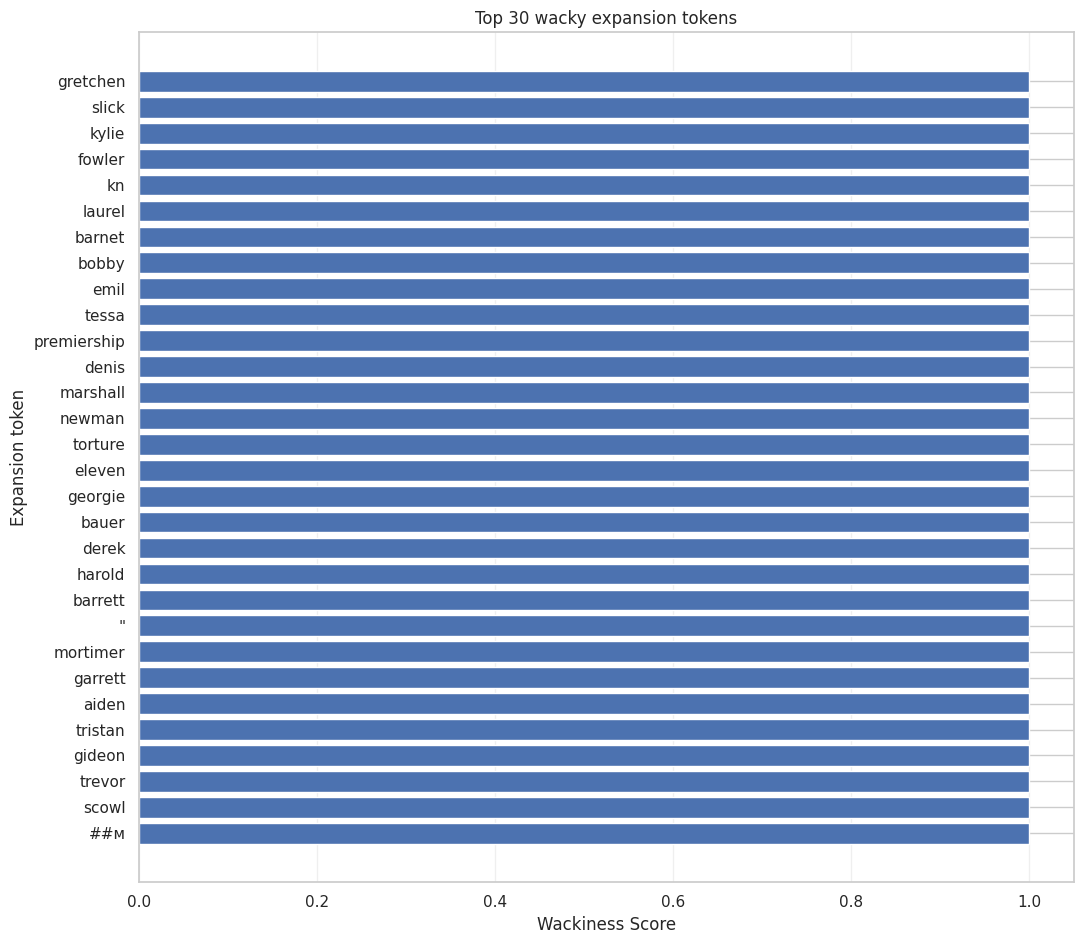

,token,wackiness_score,mean_lexical_utility,expansion_occurrences,lexical_df,lexical_idf
0,##м,1.0,0.0,46,10,9.476543
1,scowl,1.0,0.0,34,2,11.085981
2,trevor,1.0,0.0,31,20,8.783396
3,gideon,1.0,0.0,31,8,9.699687
4,tristan,1.0,0.0,26,12,9.294222
5,aiden,1.0,0.0,26,13,9.214179
6,garrett,1.0,0.0,23,31,8.345141
7,mortimer,1.0,0.0,23,3,10.680516
8,"""",1.0,0.0,21,0,0.000000
9,barrett,1.0,0.0,21,22,8.688086


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

TOP_N_PLOT = 30
plot_top = wacky_table.dropna(subset=["wackiness_score"]).head(TOP_N_PLOT).copy()
plot_top = plot_top.sort_values("wackiness_score", ascending=True)

fig, ax = plt.subplots(figsize=(11, max(7, 0.32 * len(plot_top))))
ax.barh(plot_top["token"].astype(str), plot_top["wackiness_score"])
ax.set_xlabel("Wackiness Score")
ax.set_ylabel("Expansion token")
ax.set_title(f"Top {len(plot_top)} wacky expansion tokens")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

display(
    wacky_table.head(TOP_N_PLOT)[
        ["token", "wackiness_score", "mean_lexical_utility",
         "expansion_occurrences", "lexical_df", "lexical_idf"]
    ]
)

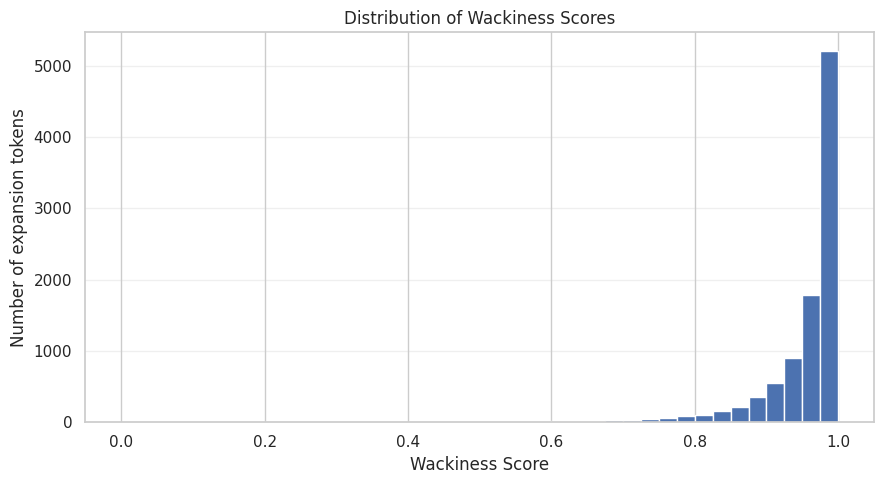

Score quantiles:


,wackiness_score
0.00,0.000000
0.10,0.883694
0.25,0.944450
0.50,0.978503
0.75,0.994149
0.90,1.000000
1.00,1.000000


In [ ]:
score_values = wacky_table["wackiness_score"].dropna().to_numpy()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(score_values, bins=40)
ax.set_xlabel("Wackiness Score")
ax.set_ylabel("Number of expansion tokens")
ax.set_title("Distribution of Wackiness Scores")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Score quantiles:")
display(wacky_table["wackiness_score"].quantile([0, .1, .25, .5, .75, .9, 1]).to_frame("wackiness_score"))

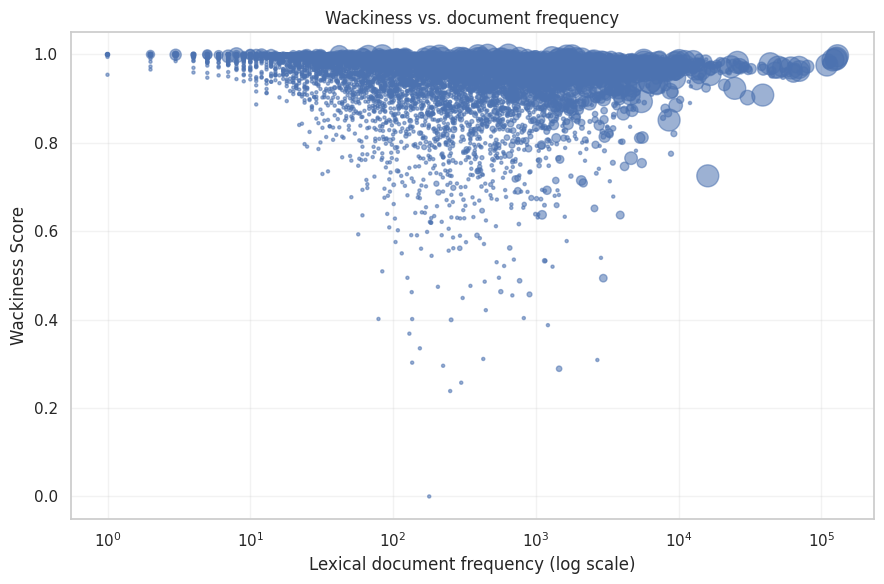

In [ ]:
scatter_df = wacky_table.dropna(
    subset=["wackiness_score", "lexical_df", "expansion_occurrences"]
).copy()

fig, ax = plt.subplots(figsize=(9, 6))
points = ax.scatter(
    scatter_df["lexical_df"],
    scatter_df["wackiness_score"],
    s=np.clip(scatter_df["expansion_occurrences"], 5, 250),
    alpha=0.55
)
ax.set_xscale("log")
ax.set_xlabel("Lexical document frequency (log scale)")
ax.set_ylabel("Wackiness Score")
ax.set_title("Wackiness vs. document frequency")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

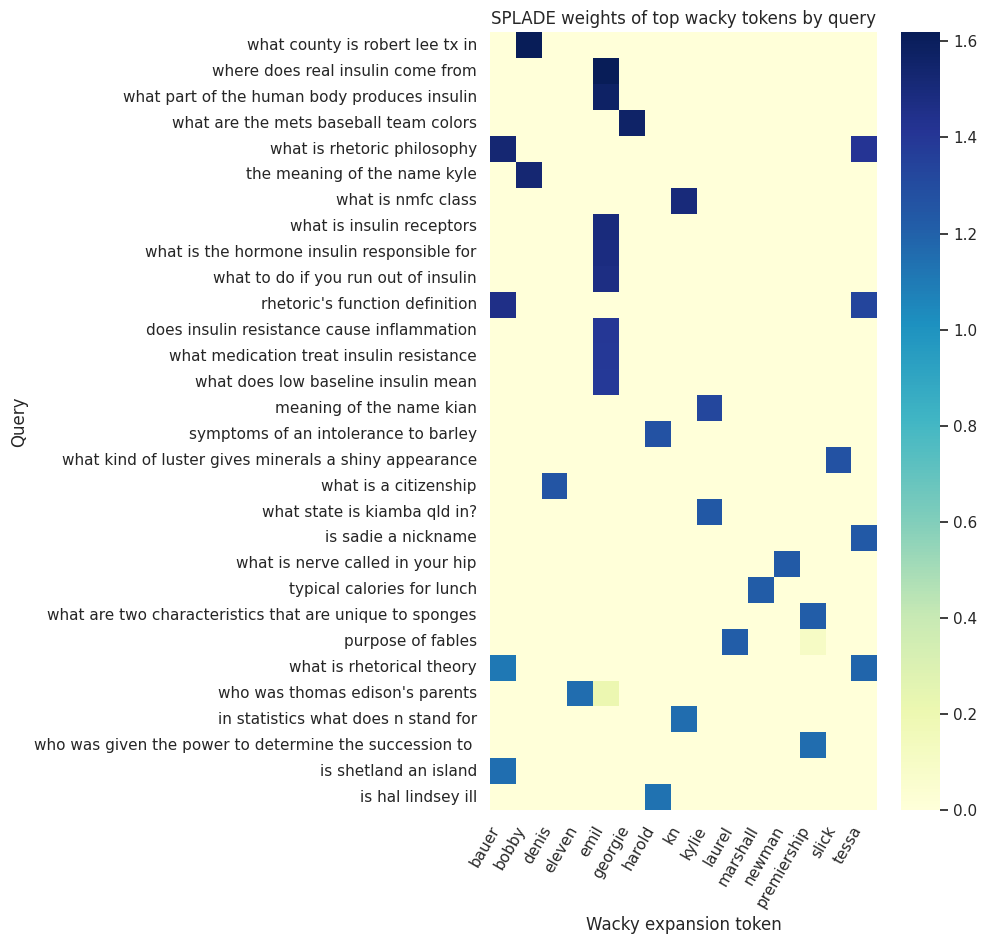

In [ ]:
if len(examples) and len(plot_top):
    selected_tokens = plot_top["token_id"].tolist()[-min(20, len(plot_top)):]
    token_labels = dict(zip(wacky_table["token_id"], wacky_table["token"]))
    heat_df = examples[examples["token_id"].isin(selected_tokens)].copy()

    heat_df["query_label"] = heat_df["query"].astype(str).str.slice(0, 55)
    heat_df = heat_df.sort_values(
        ["wackiness_score", "splade_weight"],
        ascending=[False, False]
    ).drop_duplicates(["query_label", "token_id"])

    query_order = heat_df["query_label"].drop_duplicates().head(30).tolist()
    heat_df = heat_df[heat_df["query_label"].isin(query_order)]
    heat = heat_df.pivot_table(
        index="query_label",
        columns="token",
        values="splade_weight",
        aggfunc="max",
        fill_value=0
    )

    if not heat.empty:
        heat = heat.reindex(index=query_order)
        fig, ax = plt.subplots(
            figsize=(max(10, 0.65 * len(heat.columns)), max(6, 0.32 * len(heat.index)))
        )
        sns.heatmap(heat, cmap="YlGnBu", ax=ax)
        ax.set_xlabel("Wacky expansion token")
        ax.set_ylabel("Query")
        ax.set_title("SPLADE weights of top wacky tokens by query")
        plt.xticks(rotation=60, ha="right")
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()
    else:
        print("Недостаточно данных для heatmap.")
else:
    print("Нет примеров для построения heatmap.")

In [ ]:
PLOT_DIR = OUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)


fig, ax = plt.subplots(figsize=(11, max(7, 0.32 * len(plot_top))))
ax.barh(plot_top["token"].astype(str), plot_top["wackiness_score"])
ax.set_xlabel("Wackiness Score")
ax.set_ylabel("Expansion token")
ax.set_title(f"Top {len(plot_top)} wacky expansion tokens")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
fig.savefig(PLOT_DIR / "top_wacky_tokens.png", dpi=180, bbox_inches="tight")
plt.close(fig)


fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(score_values, bins=40)
ax.set_xlabel("Wackiness Score")
ax.set_ylabel("Number of expansion tokens")
ax.set_title("Distribution of Wackiness Scores")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(PLOT_DIR / "wackiness_distribution.png", dpi=180, bbox_inches="tight")
plt.close(fig)


fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    scatter_df["lexical_df"],
    scatter_df["wackiness_score"],
    s=np.clip(scatter_df["expansion_occurrences"], 5, 250),
    alpha=0.55
)
ax.set_xscale("log")
ax.set_xlabel("Lexical document frequency (log scale)")
ax.set_ylabel("Wackiness Score")
ax.set_title("Wackiness vs. document frequency")
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(PLOT_DIR / "wackiness_vs_df.png", dpi=180, bbox_inches="tight")
plt.close(fig)

wacky_table.head(100).to_csv(OUT_DIR / "top_100_wacky_tokens.csv", index=False)
print("Saved plots to:", PLOT_DIR)
print("Saved top-token table to:", OUT_DIR / "top_100_wacky_tokens.csv")

Saved plots to: /kaggle/working/wacky_results/plots
Saved top-token table to: /kaggle/working/wacky_results/top_100_wacky_tokens.csv


In [13]:


import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display


ATTACK_CSV = Path("/kaggle/input/datasets/ulianaandrosova/top-attack-tokens/top_attack_tokens.csv")

WACKY_CSV = Path("/kaggle/working/wacky_results/wackiness_scores_repo_aligned.csv")


attack_df = pd.read_csv(ATTACK_CSV)
wacky_df = pd.read_csv(WACKY_CSV)

print("Attack columns:", attack_df.columns.tolist())
print("Wacky columns:", wacky_df.columns.tolist())


token_id_candidates = ["token_id", "term_id", "id"]
token_candidates = ["token", "term", "token_str", "expansion_token"]
score_candidates = ["wackiness", "wackiness_score", "wacky_score"]

def find_column(df, candidates, description):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(
        f"Не найдена колонка {description}. "
        f"Доступные колонки: {df.columns.tolist()}"
    )

wacky_id_col = find_column(wacky_df, token_id_candidates, "token ID")
wacky_token_col = next(
    (c for c in token_candidates if c in wacky_df.columns), None
)
wacky_score_col = find_column(wacky_df, score_candidates, "wackiness score")


top20 = (
    attack_df
    .sort_values(["direction", "rank_in_direction"])
    .groupby("direction", group_keys=False)
    .head(20)
    .copy()
)


top20["token_id"] = pd.to_numeric(top20["token_id"], errors="coerce")
wacky_df[wacky_id_col] = pd.to_numeric(
    wacky_df[wacky_id_col], errors="coerce"
)


wacky_lookup = wacky_df[
    [wacky_id_col, wacky_score_col]
].dropna(subset=[wacky_id_col]).drop_duplicates(wacky_id_col)

wacky_lookup = wacky_lookup.rename(columns={
    wacky_id_col: "token_id",
    wacky_score_col: "wackiness"
})


result = top20.merge(wacky_lookup, on="token_id", how="left")


if wacky_token_col is not None:
    token_lookup = (
        wacky_df[[wacky_id_col, wacky_token_col]]
        .dropna(subset=[wacky_id_col])
        .drop_duplicates(wacky_id_col)
        .rename(columns={
            wacky_id_col: "token_id",
            wacky_token_col: "wacky_token"
        })
    )
    result = result.merge(token_lookup, on="token_id", how="left")
else:
    result["wacky_token"] = np.nan


print(f"\nTop attack tokens: {len(result)}")
print(f"Matched wackiness scores: {result['wackiness'].notna().sum()}")
print(f"Unmatched tokens: {result['wackiness'].isna().sum()}")

preferred_cols = [
    "direction", "rank_in_direction", "token", "token_id",
    "wackiness", "wacky_token", "loo_contrib_mean",
    "loo_nrs_drop_mean", "transfer_nrs_mean",
    "transfer_success_rate", "splade_doc_df"
]
show_cols = [c for c in preferred_cols if c in result.columns]

display(
    result[show_cols]
    .sort_values(["direction", "rank_in_direction"])
    .reset_index(drop=True)
)


summary = (
    result.groupby("direction")
    .agg(
        n_tokens=("token_id", "size"),
        n_wackiness_available=("wackiness", "count"),
        mean_wackiness=("wackiness", "mean"),
        median_wackiness=("wackiness", "median"),
        mean_transfer_nrs=("transfer_nrs_mean", "mean"),
        mean_loo_impact=("loo_contrib_mean", "mean"),
    )
    .reset_index()
)

display(summary)

# 9. Save merged results
OUT = Path("/kaggle/working/attack_results/top20_attack_tokens_with_wackiness.csv")
result[show_cols].to_csv(OUT, index=False)
print(f"Saved: {OUT}")

Attack columns: ['direction', 'rank_in_direction', 'token', 'token_id', 'n_triggers', 'n_queries', 'mean_nrs_with_token', 'loo_n', 'loo_contrib_mean', 'loo_contrib_sum', 'loo_nrs_drop_mean', 'transfer_nrs_mean', 'transfer_success_rate', 'splade_doc_df', 'n_experiments', 'transfer_score_gain_mean', 'is_subword']
Wacky columns: ['token_id', 'token', 'expansion_occurrences', 'mean_lexical_utility', 'normalized_lexical_utility', 'wackiness_score', 'zero_utility_fraction', 'lexical_df', 'lexical_idf', 'splade_df']

Top attack tokens: 40
Matched wackiness scores: 26
Unmatched tokens: 14


,direction,rank_in_direction,token,token_id,wackiness,wacky_token,loo_contrib_mean,loo_nrs_drop_mean,transfer_nrs_mean,transfer_success_rate,splade_doc_df
0,demotion,1,means,2965,0.968454,means,1.166179,0.242755,0.130121,0.630,29885
1,demotion,2,definition,6210,0.966810,definition,1.689548,0.339754,0.119575,0.630,25064
2,demotion,3,noun,15156,0.786039,noun,1.724953,0.230484,0.150390,0.600,3124
3,demotion,4,choral,14564,NaN,NaN,0.687477,0.205279,0.196194,0.700,74
4,demotion,5,leeds,7873,0.910251,leeds,4.167573,0.208754,0.102663,0.580,44
5,demotion,6,gershwin,25600,NaN,NaN,0.812810,0.209700,0.181119,0.690,3
6,demotion,7,dog,3899,0.890201,dog,2.297803,0.194444,0.196721,0.760,13291
7,demotion,8,climate,4785,0.953833,climate,2.999746,0.249158,0.159526,0.680,8963
8,demotion,9,covers,4472,NaN,NaN,2.857364,0.086420,0.126727,0.610,294
9,demotion,10,caves,10614,0.921384,caves,2.845588,0.781145,0.126205,0.625,237


,direction,n_tokens,n_wackiness_available,mean_wackiness,median_wackiness,mean_transfer_nrs,mean_loo_impact
0,demotion,20,12,0.912220,0.927146,0.158162,2.997317
1,promotion,20,14,0.947515,0.970344,-0.078564,3.609740


OSError: Cannot save file into a non-existent directory: '/kaggle/working/attack_results'

In [14]:
OUT = Path("/kaggle/working/attack_results/top20_attack_tokens_with_wackiness.csv")
OUT.parent.mkdir(parents=True, exist_ok=True)

result[show_cols].to_csv(OUT, index=False)
print(f"Saved: {OUT}")

Saved: /kaggle/working/attack_results/top20_attack_tokens_with_wackiness.csv


In [16]:
from pathlib import Path
import pandas as pd
import numpy as np

ATTACK_CSV = Path(
    "/kaggle/input/datasets/ulianaandrosova/top-attack-tokens/top_attack_tokens.csv"
)
WACKY_CSV = Path(
    "/kaggle/working/wacky_results/wackiness_scores_repo_aligned.csv"
)

OUT_DIR = Path("/kaggle/working/attack_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MERGED_CSV = OUT_DIR / "attack_tokens_wackiness_merged.csv"

# Проверяем наличие файлов
assert ATTACK_CSV.exists(), f"Attack CSV не найден: {ATTACK_CSV}"
assert WACKY_CSV.exists(), f"Wacky CSV не найден: {WACKY_CSV}"

attack = pd.read_csv(ATTACK_CSV)
wacky = pd.read_csv(WACKY_CSV)

print("Attack shape:", attack.shape)
print("Wacky shape:", wacky.shape)
print("Attack columns:", attack.columns.tolist())
print("Wacky columns:", wacky.columns.tolist())

# Проверяем необходимые столбцы
required_attack = {
    "token_id", "token", "direction", "loo_contrib_mean",
    "loo_nrs_drop_mean", "transfer_nrs_mean",
    "transfer_success_rate", "splade_doc_df"
}
required_wacky = {
    "token_id", "token", "wackiness_score", "splade_df"
}

assert required_attack.issubset(attack.columns), (
    f"В attack CSV отсутствуют: {required_attack - set(attack.columns)}"
)
assert required_wacky.issubset(wacky.columns), (
    f"В wacky CSV отсутствуют: {required_wacky - set(wacky.columns)}"
)

# Если в Wacky CSV есть повторяющиеся token_id, оставляем одну запись
wacky = wacky.drop_duplicates(subset="token_id", keep="first").copy()

# Приводим ID к совместимому типу
attack["token_id"] = pd.to_numeric(attack["token_id"], errors="coerce")
wacky["token_id"] = pd.to_numeric(wacky["token_id"], errors="coerce")

attack = attack.dropna(subset=["token_id"]).copy()
wacky = wacky.dropna(subset=["token_id"]).copy()

attack["token_id"] = attack["token_id"].astype("int64")
wacky["token_id"] = wacky["token_id"].astype("int64")

# Объединяем по token_id
merged = attack.merge(
    wacky[
        [
            "token_id", "wackiness_score",
            "normalized_lexical_utility",
            "mean_lexical_utility",
            "zero_utility_fraction",
            "lexical_df", "lexical_idf", "splade_df"
        ]
    ],
    on="token_id",
    how="left",
    validate="many_to_one"
)

merged = merged.rename(columns={"wackiness_score": "wackiness"})

merged.to_csv(MERGED_CSV, index=False)

print("\nMerged shape:", merged.shape)
print("Matched wackiness:", merged["wackiness"].notna().sum())
print("Unmatched:", merged["wackiness"].isna().sum())
print("Saved:", MERGED_CSV)

display(
    merged[
        [
            "direction", "token", "token_id", "wackiness",
            "loo_contrib_mean", "loo_nrs_drop_mean",
            "transfer_nrs_mean", "transfer_success_rate"
        ]
    ].head(10)
)

Attack shape: (1241, 17)
Wacky shape: (9648, 10)
Attack columns: ['direction', 'rank_in_direction', 'token', 'token_id', 'n_triggers', 'n_queries', 'mean_nrs_with_token', 'loo_n', 'loo_contrib_mean', 'loo_contrib_sum', 'loo_nrs_drop_mean', 'transfer_nrs_mean', 'transfer_success_rate', 'splade_doc_df', 'n_experiments', 'transfer_score_gain_mean', 'is_subword']
Wacky columns: ['token_id', 'token', 'expansion_occurrences', 'mean_lexical_utility', 'normalized_lexical_utility', 'wackiness_score', 'zero_utility_fraction', 'lexical_df', 'lexical_idf', 'splade_df']

Merged shape: (1241, 24)
Matched wackiness: 598
Unmatched: 643
Saved: /kaggle/working/attack_results/attack_tokens_wackiness_merged.csv


,direction,token,token_id,wackiness,loo_contrib_mean,loo_nrs_drop_mean,transfer_nrs_mean,transfer_success_rate
0,demotion,means,2965,0.968454,1.166179,0.242755,0.130121,0.630
1,demotion,definition,6210,0.966810,1.689548,0.339754,0.119575,0.630
2,demotion,noun,15156,0.786039,1.724953,0.230484,0.150390,0.600
3,demotion,choral,14564,NaN,0.687477,0.205279,0.196194,0.700
4,demotion,leeds,7873,0.910251,4.167573,0.208754,0.102663,0.580
5,demotion,gershwin,25600,NaN,0.812810,0.209700,0.181119,0.690
6,demotion,dog,3899,0.890201,2.297803,0.194444,0.196721,0.760
7,demotion,climate,4785,0.953833,2.999746,0.249158,0.159526,0.680
8,demotion,covers,4472,NaN,2.857364,0.086420,0.126727,0.610
9,demotion,caves,10614,0.921384,2.845588,0.781145,0.126205,0.625


In [17]:
import pandas as pd
import numpy as np
from pathlib import Path

ATTACK_CSV = Path(
    "/kaggle/input/datasets/ulianaandrosova/top-attack-tokens/top_attack_tokens.csv"
)
WACKY_CSV = Path(
    "/kaggle/working/wacky_results/wackiness_scores_repo_aligned.csv"
)

OUT_DIR = Path("/kaggle/working/attack_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MERGED_CSV = OUT_DIR / "attack_tokens_wackiness_merged.csv"
CONTROL_CSV = OUT_DIR / "attack_vs_frequency_matched_controls.csv"

rng = np.random.default_rng(42)

attack = pd.read_csv(ATTACK_CSV)
wacky = pd.read_csv(WACKY_CSV)

attack["token_id"] = pd.to_numeric(attack["token_id"], errors="coerce")
wacky["token_id"] = pd.to_numeric(wacky["token_id"], errors="coerce")
attack = attack.dropna(subset=["token_id"]).copy()
wacky = wacky.dropna(subset=["token_id", "wackiness_score", "splade_df"]).copy()

attack["token_id"] = attack["token_id"].astype("int64")
wacky["token_id"] = wacky["token_id"].astype("int64")
wacky = wacky.drop_duplicates(subset="token_id", keep="first")


attack_wacky = attack.merge(
    wacky[["token_id", "wackiness_score", "splade_df"]],
    on="token_id",
    how="left",
    validate="many_to_one"
).rename(columns={"wackiness_score": "wackiness"})


attack_valid = attack_wacky.dropna(
    subset=["wackiness", "splade_doc_df"]
).copy()

attack_valid["df_bin"] = np.floor(
    np.log10(attack_valid["splade_doc_df"].clip(lower=1))
).astype(int)

control_pool = wacky.copy()
control_pool["df_bin"] = np.floor(
    np.log10(control_pool["splade_df"].clip(lower=1))
).astype(int)

attack_ids = set(attack_valid["token_id"])
results = []

for _, row in attack_valid.iterrows():
    
    candidates = control_pool[
        (control_pool["df_bin"] == row["df_bin"])
        & (~control_pool["token_id"].isin(attack_ids))
    ]

  
    if candidates.empty:
        candidates = control_pool[
            (control_pool["df_bin"] - row["df_bin"]).abs().le(1)
            & (~control_pool["token_id"].isin(attack_ids))
        ]

    if candidates.empty:
        continue

    
    ctrl = candidates.iloc[rng.integers(0, len(candidates))]

    results.append({
        "direction": row.get("direction"),
        "attack_token": row.get("token"),
        "attack_token_id": row["token_id"],
        "attack_df": row["splade_doc_df"],
        "attack_wackiness": row["wackiness"],
        "control_token": ctrl["token"],
        "control_token_id": ctrl["token_id"],
        "control_df": ctrl["splade_df"],
        "control_wackiness": ctrl["wackiness_score"],
        "wackiness_difference": row["wackiness"] - ctrl["wackiness_score"],
        "loo_contrib_mean": row.get("loo_contrib_mean"),
        "loo_nrs_drop_mean": row.get("loo_nrs_drop_mean"),
        "transfer_nrs_mean": row.get("transfer_nrs_mean"),
        "transfer_success_rate": row.get("transfer_success_rate")
    })

control_df = pd.DataFrame(results)
control_df.to_csv(CONTROL_CSV, index=False)

print("Matched pairs:", len(control_df))
print("Saved:", CONTROL_CSV)

if not control_df.empty:
    print("\nOverall comparison:")
    display(control_df[
        ["attack_wackiness", "control_wackiness", "wackiness_difference"]
    ].describe())

    print("\nBy direction:")
    display(
        control_df.groupby("direction")[
            ["attack_wackiness", "control_wackiness", "wackiness_difference"]
        ].agg(["count", "mean", "median", "std"]).round(4)
    )
else:
    print("Не удалось подобрать контрольные токены.")

Matched pairs: 598
Saved: /kaggle/working/attack_results/attack_vs_frequency_matched_controls.csv

Overall comparison:


,attack_wackiness,control_wackiness,wackiness_difference
count,598.000000,598.000000,598.000000
mean,0.947183,0.957554,-0.010372
std,0.067965,0.060186,0.092753
min,0.401346,0.463325,-0.595945
25%,0.933864,0.945596,-0.040682
50%,0.970868,0.977421,-0.003894
75%,0.988768,0.992897,0.024449
max,1.000000,1.000000,0.532767



By direction:


attack_wackiness                         control_wackiness          \
                     count    mean  median     std             count    mean   
direction                                                                      
demotion               288  0.9427  0.9673  0.0728               288  0.9624   
promotion              310  0.9514  0.9745  0.0629               310  0.9530   

                          wackiness_difference                          
           median     std                count    mean  median     std  
direction                                                               
demotion   0.9778  0.0522                  288 -0.0198 -0.0070  0.0912  
promotion  0.9770  0.0665                  310 -0.0017 -0.0011  0.0935

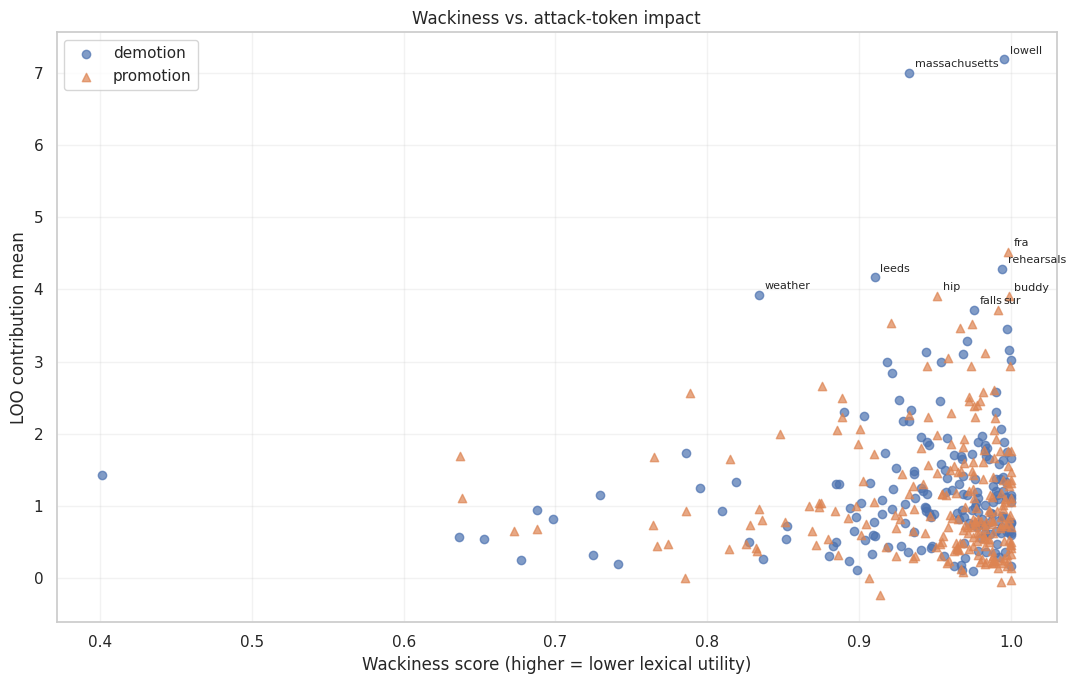

Saved: /kaggle/working/attack_results/wackiness_vs_loo_impact.png


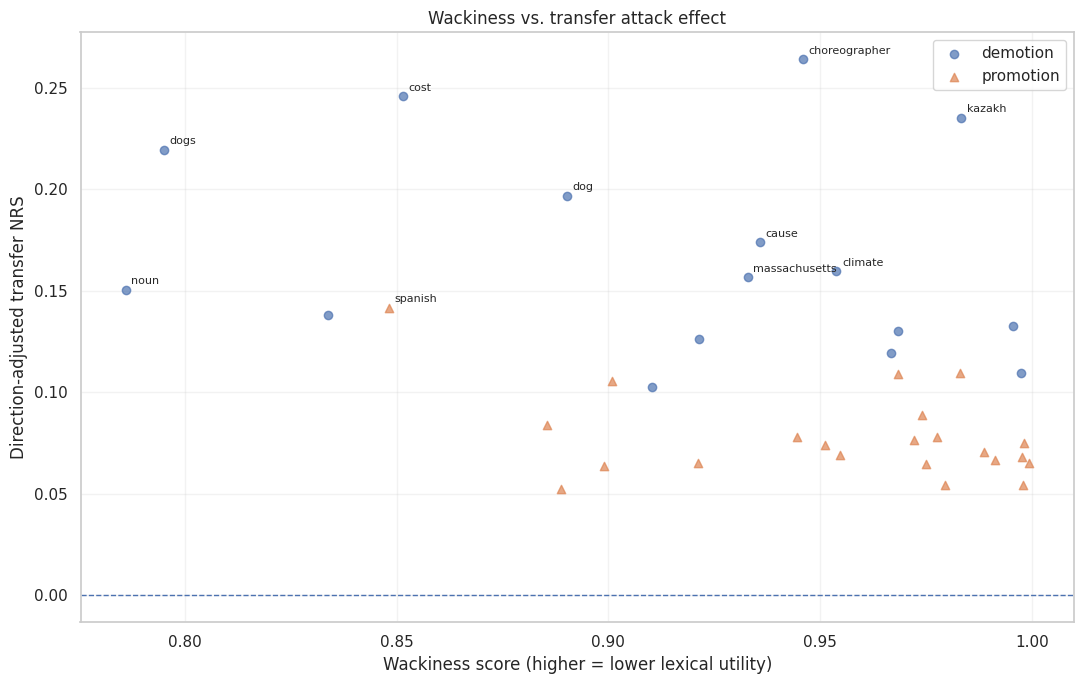

Saved: /kaggle/working/attack_results/wackiness_vs_transfer_effect.png
Saved: /kaggle/working/attack_results/wackiness_attack_correlations.csv


,direction,metric,n,spearman_rho,p_value
0,demotion,loo_contrib_mean,180,0.0982,0.1897
1,demotion,loo_nrs_drop_mean,180,0.1111,0.1376
2,demotion,transfer_nrs_mean,16,-0.2559,0.3388
3,demotion,direction_adjusted_transfer,16,-0.2559,0.3388
4,demotion,transfer_success_rate,16,-0.0738,0.7859
5,promotion,loo_contrib_mean,228,-0.0661,0.3202
6,promotion,loo_nrs_drop_mean,228,-0.0284,0.6699
7,promotion,transfer_nrs_mean,22,0.2242,0.3159
8,promotion,direction_adjusted_transfer,22,-0.2242,0.3159
9,promotion,transfer_success_rate,22,0.2986,0.1771


In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

OUT_DIR = Path("/kaggle/working/attack_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MERGED_CSV = OUT_DIR / "attack_tokens_wackiness_merged.csv"
PLOT_CSV = OUT_DIR / "wackiness_attack_correlations.csv"
FIG1 = OUT_DIR / "wackiness_vs_loo_impact.png"
FIG2 = OUT_DIR / "wackiness_vs_transfer_effect.png"

df = pd.read_csv(MERGED_CSV)

numeric_cols = [
    "wackiness", "loo_contrib_mean", "loo_nrs_drop_mean",
    "transfer_nrs_mean", "transfer_success_rate"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["wackiness"]).copy()


df["direction_adjusted_transfer"] = np.where(
    df["direction"].astype(str).str.lower().eq("demotion"),
    df["transfer_nrs_mean"],
    -df["transfer_nrs_mean"]
)


plot1 = df.dropna(subset=["wackiness", "loo_contrib_mean"]).copy()

fig, ax = plt.subplots(figsize=(11, 7))

for direction, marker in [("demotion", "o"), ("promotion", "^")]:
    sub = plot1[plot1["direction"].astype(str).str.lower() == direction]
    if not sub.empty:
        ax.scatter(
            sub["wackiness"],
            sub["loo_contrib_mean"],
            alpha=0.7,
            marker=marker,
            label=direction
        )

labels = plot1.nlargest(min(10, len(plot1)), "loo_contrib_mean")
for _, row in labels.iterrows():
    ax.annotate(
        str(row["token"]),
        (row["wackiness"], row["loo_contrib_mean"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Wackiness score (higher = lower lexical utility)")
ax.set_ylabel("LOO contribution mean")
ax.set_title("Wackiness vs. attack-token impact")
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIG1, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", FIG1)

plot2 = df.dropna(
    subset=["wackiness", "direction_adjusted_transfer"]
).copy()

fig, ax = plt.subplots(figsize=(11, 7))

for direction, marker in [("demotion", "o"), ("promotion", "^")]:
    sub = plot2[plot2["direction"].astype(str).str.lower() == direction]
    if not sub.empty:
        ax.scatter(
            sub["wackiness"],
            sub["direction_adjusted_transfer"],
            alpha=0.7,
            marker=marker,
            label=direction
        )

labels = plot2.nlargest(
    min(10, len(plot2)),
    "direction_adjusted_transfer"
)
for _, row in labels.iterrows():
    ax.annotate(
        str(row["token"]),
        (row["wackiness"], row["direction_adjusted_transfer"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Wackiness score (higher = lower lexical utility)")
ax.set_ylabel("Direction-adjusted transfer NRS")
ax.set_title("Wackiness vs. transfer attack effect")
ax.axhline(0, linewidth=1, linestyle="--")
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIG2, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", FIG2)


metrics = [
    "loo_contrib_mean",
    "loo_nrs_drop_mean",
    "transfer_nrs_mean",
    "direction_adjusted_transfer",
    "transfer_success_rate"
]

rows = []

for direction, sub in df.groupby("direction"):
    for metric in metrics:
        valid = sub[["wackiness", metric]].dropna()

        if len(valid) >= 3 and valid["wackiness"].nunique() > 1 and valid[metric].nunique() > 1:
            rho, p_value = spearmanr(valid["wackiness"], valid[metric])
        else:
            rho, p_value = np.nan, np.nan

        rows.append({
            "direction": direction,
            "metric": metric,
            "n": len(valid),
            "spearman_rho": rho,
            "p_value": p_value
        })

corr_df = pd.DataFrame(rows)
corr_df.to_csv(PLOT_CSV, index=False)

print("Saved:", PLOT_CSV)
display(corr_df.round(4))